https://www.kaggle.com/code/onurkoc83/quantum-machine-learning-tutorial

In [85]:
import pandas as pd
from sklearn import model_selection, datasets, svm
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime import QiskitRuntimeService
import matplotlib.pyplot as plt

In [86]:
%matplotlib inline

In [87]:
df = pd.read_csv('Heart_data.csv')
df.head()

,Age,Gender,BloodPressure,Cholesterol,HeartRate,QuantumPatternFeature,HeartDisease
0,68,1,105,191,107,8.362241,1
1,58,0,97,249,89,9.249002,0
2,44,0,93,190,82,7.942542,1
3,72,1,93,183,101,6.495155,1
4,37,0,145,166,103,7.653900,1


In [88]:
X = df[['Age', 'Gender', 'BloodPressure', 'Cholesterol', 'HeartRate', 'QuantumPatternFeature']].values
Y = df['HeartDisease'].values

X_train, X_test, Y_train, Y_test = model_selection.train_test_split(
    X, Y, test_size=0.33, random_state=42
)

In [89]:
X_train = (X_train - X_train.min(0)) / (X_train.max(0) - X_train.min(0) + 1e-12)
X_test  = (X_test  - X_train.min(0)) / (X_train.max(0) - X_train.min(0) + 1e-12)

In [90]:
Y_train

array([1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0,
       1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0,
       1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0,
       1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1,
       1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1,
       0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1,
       1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1,
       1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1,
       0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0,
       1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0,
       1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1,
       0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1,
       0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1,

In [91]:
print("First training sample:")
print(X_train[0])

First training sample:
[0.95918367 0.         0.08988764 0.62162162 0.03389831 0.32205274]


In [92]:
print(X_train[0])

[0.95918367 0.         0.08988764 0.62162162 0.03389831 0.32205274]


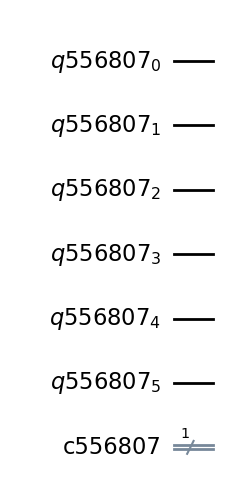

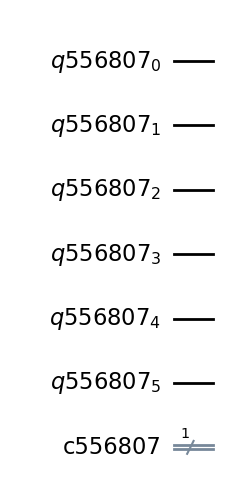

In [93]:
N = X.shape[1]
q = QuantumRegister(N)
c = ClassicalRegister(1)
qc = QuantumCircuit(q, c)

qc.draw("mpl")

the rx refers to the RX gate in Qiskit, which is a single-qubit rotation gate applied to a quantum circuit (qc). Specifically, it rotates the qubit’s state around the X-axis of the Bloch sphere by an angle specified by the parameter x.  X is the Pauli-X matrix.

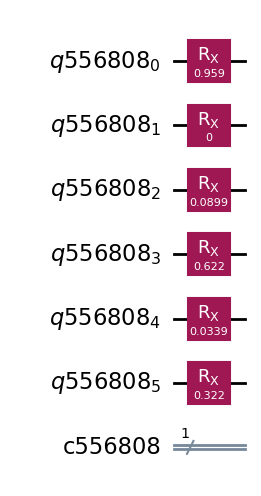

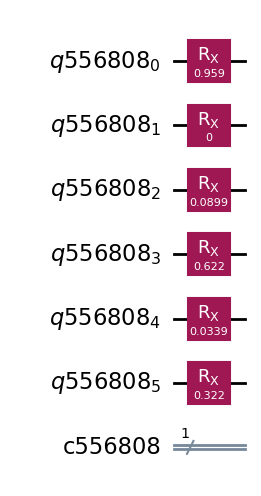

In [94]:
N = X.shape[1]
q = QuantumRegister(N)
c = ClassicalRegister(1)
qc = QuantumCircuit(q, c)

for i, x in enumerate(X_train[0]):
    qc.rx(x, i)

qc.draw("mpl")

In [95]:
N = X.shape[1]
def feature_map(X):

    q = QuantumRegister(N)
    c = ClassicalRegister(1)
    qc = QuantumCircuit(q, c)

    for i, x in enumerate(X):
        qc.rx(x, i)
    return qc, c 

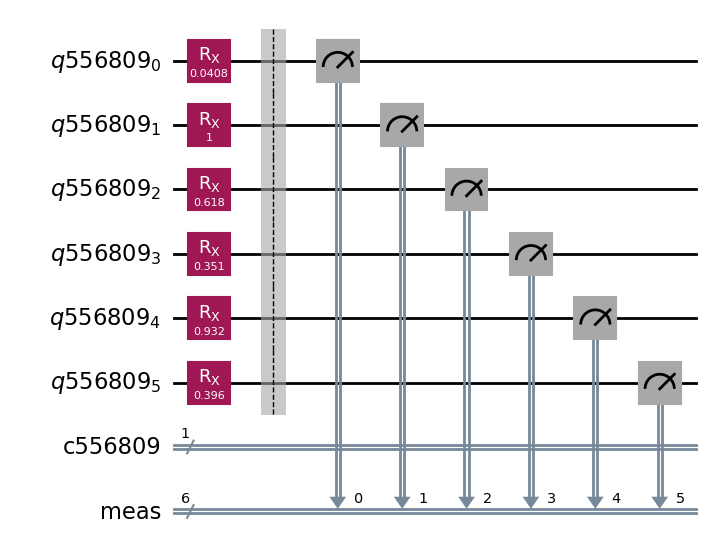

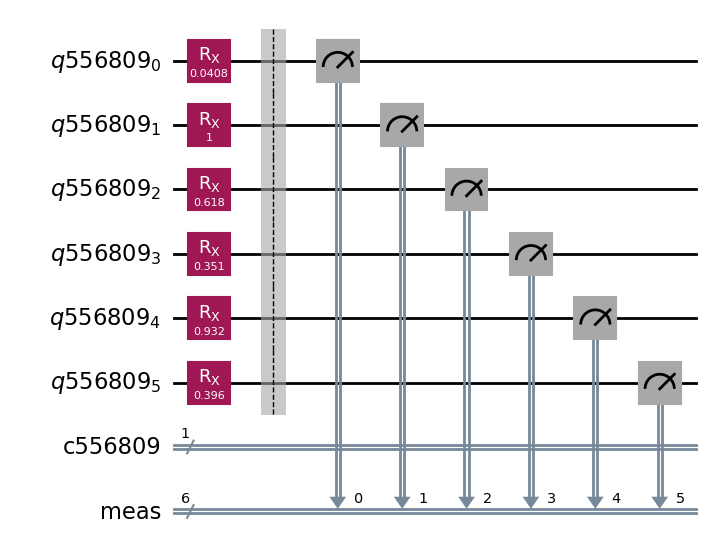

In [96]:
qc, c =feature_map(X_train[5])


# measurement operator
#qc.measure(0,c)
qc.measure_all()

qc.draw("mpl")

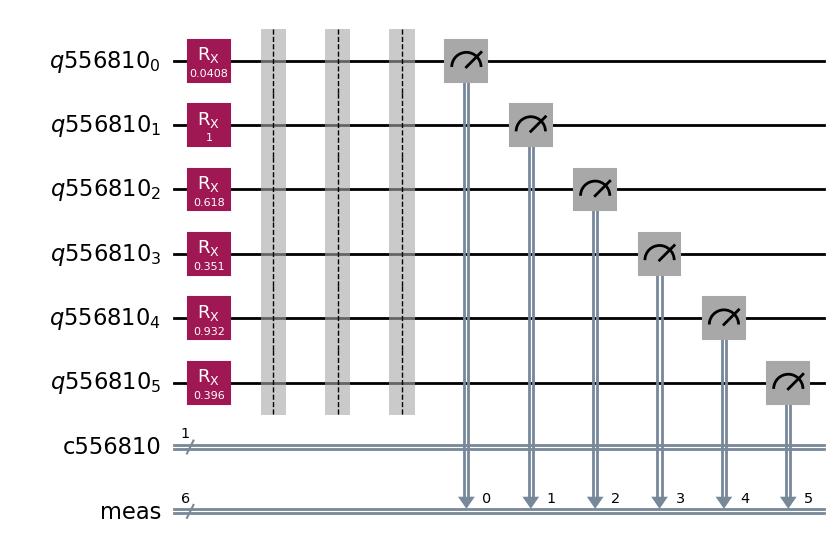

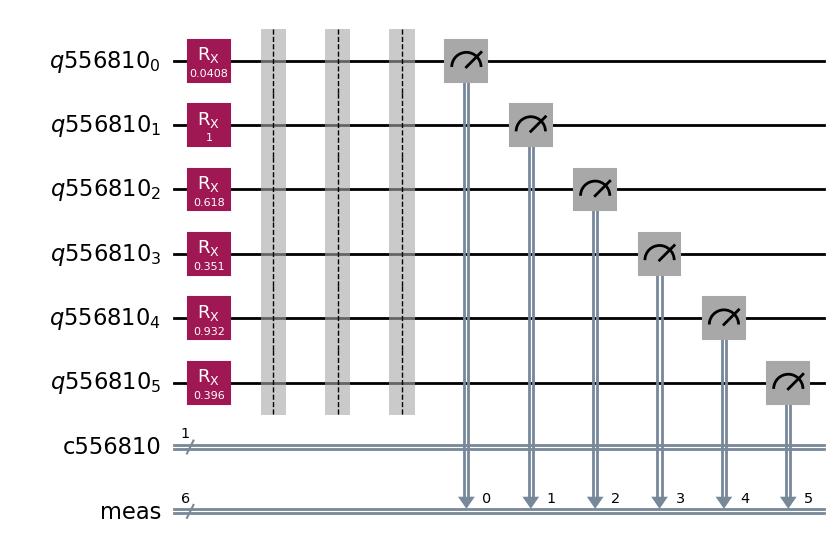

In [97]:
qc, c =feature_map(X_train[5])

qc.barrier()

qc.barrier()

# measurement operator
#qc.measure(0,c)
qc.measure_all()

qc.draw("mpl")

In [98]:
print(Y_train[5])

1


Variational Circuits

In [99]:
def variational_circuit(qc, theta):
    N = qc.num_qubits  # Get the number of qubits directly from the circuit

    # Apply CNOT gates between adjacent qubits (Linear Entangler)
    for i in range(N - 1):
        # Correct: use qc.cx() instead of qc.cnot()
        qc.cx(i, i + 1)

    # Apply CNOT gate from the last to the first qubit (Periodic Entangler)
    # Correct: use qc.cx() instead of qc.cnot()
    qc.cx(N - 1, 0)
    
    # Apply RY rotation to every qubit
    for i in range(N):
        qc.ry(theta[i], i)
        
    return qc

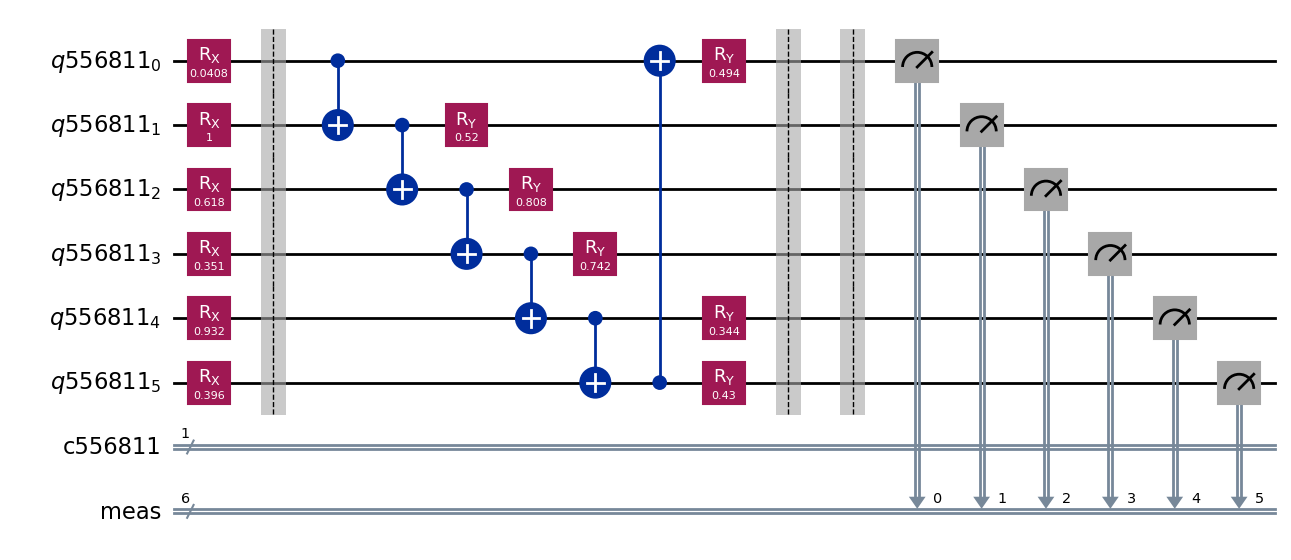

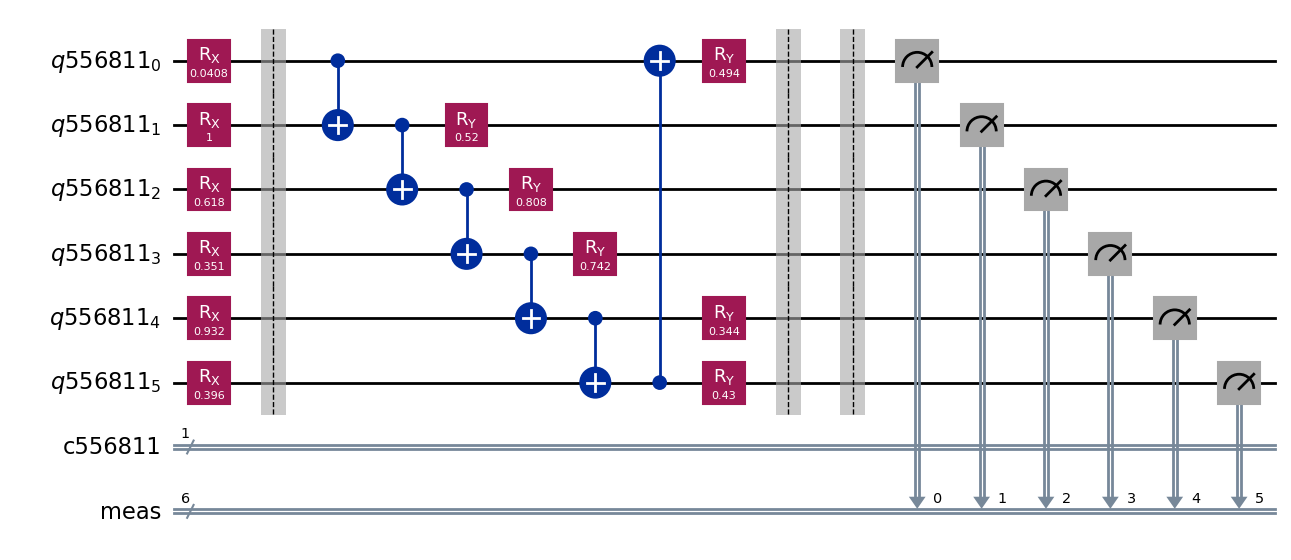

In [100]:
import numpy as np
qc, c =feature_map(X_train[5])

qc.barrier()

qc = variational_circuit(qc, np.random.rand(N))

qc.barrier()

# measurement operator
#qc.measure(0,c)
qc.measure_all()

qc.draw("mpl")

Blue line are circuits not gates. they create entanglement, so they essentially allow information to travel from one qubit to another

In [101]:
print(Y_train[5])

1


In [102]:
def quantum_nn(X, theta, simulator=True):
    qc, _ = feature_map(X)
    qc = variational_circuit(qc, theta)
    qc.measure_all()                     # ← MEASURES ALL QUBITS
    
    shots = 10000
    backend = AerSimulator()
    result = backend.run(qc, shots=shots).result()
    counts = result.get_counts(qc)
    
    # Parity of number of 1s → classification
    prob_class_1 = sum(v for k, v in counts.items() if k.count('1') % 2 == 1) / shots
    return prob_class_1

In [103]:
prediction = quantum_nn(X_train[5], np.random.rand(N))
prediction

0.4115

In [104]:
target = Y_train[5]
target

np.int64(1)

In [105]:
(target - prediction)**2

np.float64(0.34633225)

In [106]:
def loss(prediction, target):
      return (target - prediction)**2

In [107]:
loss(prediction, target)

np.float64(0.34633225)

Stochastic gradient descent rule:
 - minimize loss function
 - loop over training data
 - update variational parameters 
 - use loss function to update theta

In [108]:
import copy

def gradient(X, Y, theta):
    
      delta = 0.01

      grad = []
    
      for i in range(len(theta)):

          dtheta = copy.copy(theta)  # shallow copy
          dtheta[i] += delta

          pred1 = quantum_nn(X, dtheta)
          pred2 = quantum_nn(X, theta)
          # finite difference
          grad.append( (loss(pred1, Y)-loss(pred2, Y))/ delta)

      return np.array(grad)

In [109]:
def accuracy(X, Y, theta):

      counter = 0
      for X_i, Y_i in zip(X, Y):

          prediction = quantum_nn(X_i, theta)

          if prediction < 0.5 and Y_i == 0:
               counter +=1
          elif prediction >= 0.5 and Y_i == 1:
               counter +=1
      return counter/len(Y)

In [110]:
eta = 0.1
theta = np.random.randn(N)
loss_list = []

print("Epoch \t Loss \t Training Accuracy")
for i in range(50):
    loss_tmp = []
    for X_i, Y_i in zip(X_train, Y_train):
        prediction = quantum_nn(X_i, theta)        # now X_i is in [0,1] → perfect
        loss_tmp.append(loss(prediction, Y_i))
        theta = theta - eta * gradient(X_i, Y_i, theta)
   
    loss_list.append(np.mean(loss_tmp))
    acc = accuracy(X_train, Y_train, theta)
    print(f"{i+1:2d} \t {loss_list[-1]:.4f} \t {acc:.4f}")

Epoch 	 Loss 	 Training Accuracy
 1 	 0.2507 	 0.5224
 2 	 0.2514 	 0.4836
 3 	 0.2525 	 0.4209
 4 	 0.2510 	 0.4985
 5 	 0.2472 	 0.5970
 6 	 0.2523 	 0.4597
 7 	 0.2515 	 0.5284
 8 	 0.2558 	 0.4090
 9 	 0.2552 	 0.4299
10 	 0.2499 	 0.4388
11 	 0.2546 	 0.4955
12 	 0.2513 	 0.5791
13 	 0.2516 	 0.5164
14 	 0.2520 	 0.4418
15 	 0.2511 	 0.4209
16 	 0.2562 	 0.5851
17 	 0.2485 	 0.4537
18 	 0.2502 	 0.4597
19 	 0.2509 	 0.4806


KeyboardInterrupt: 

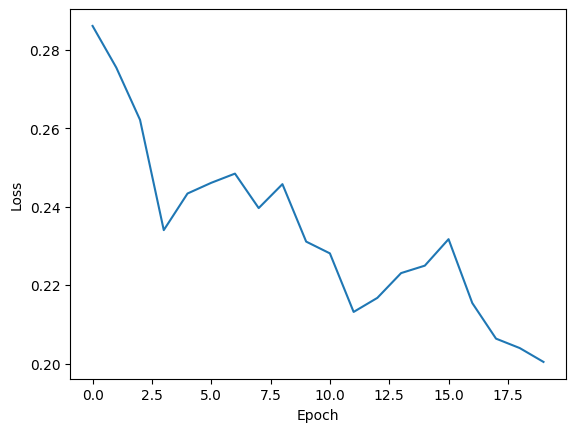

In [30]:
import matplotlib.pyplot as plt

plt.plot(loss_list)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

In [31]:
accuracy(X_test, Y_test, theta)

0.7575757575757576

In [32]:
clf = svm.SVC()
clf.fit(X_train, Y_train)

print(clf.predict(X_test))
print(Y_test)

[1 1 1 0 0 0 0 1 0 0 0 0 1 0 1 0 1 1 0 0 1 1 0 0 1 0 0 1 0 1 0 0 1]
[1 1 1 0 0 0 0 1 0 0 0 0 1 0 1 0 1 1 0 0 1 1 0 0 1 0 0 1 0 1 0 0 1]
